# ChaCha20 auf dem CW-Lite (STM32F3): Test & erste Traces

Dieses Notebook testet die Firmware `firmware/mcu/simpleserial-chacha20`, also ChaCha20 in der **IETF-Variante** (RFC 8439: 96-Bit-Nonce, 32-Bit-Counter).

**Ablauf:**
1. Setup: Scope und Target verbinden
2. Firmware bauen und flashen
3. Referenz (pycryptodome) gegen die RFC-8439-Testvektoren prüfen
4. Target gegen die Referenz validieren
5. Trace-Länge bestimmen (passt der Block ins Sample-Fenster?)
6. Traces aufnehmen und speichern (fester Schlüssel, zufällige Nonce und zufälliger Counter, Grundlage für eine spätere CPA)

**SimpleSerial-Befehle der Firmware:**

| Befehl | Länge | Funktion |
|---|---|---|
| `'k'` | 32 B | Schlüssel setzen |
| `'n'` | 16 B | Counter (4 B, little endian) und Nonce (12 B) |
| `'p'` | 16 B | 16 B Klartext verschlüsseln, Antwort `'r'` mit 16 B |
| `'x'` | 0 B | Schlüssel, Nonce und Counter auf null setzen |

## 1. Setup

In [2]:
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CWLITEARM'    #STM32
SS_VER    = 'SS_VER_1_1'

FW_DIR = "../../firmware/mcu/simpleserial-chacha20"

%run "../Setup_Scripts/Setup_Generic.ipynb"


INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 30                       
scope.gain.db                            changed from 5.5                       to 24.8359375               
scope.adc.basic_mode                     changed from low                       to rising_edge              
scope.adc.samples                        changed from 24400                     to 5000                     
scope.adc.trig_count                     changed from 7200658                   to 20795118                 
scope.clock.adc_src                      changed from clkgen_x1                 to clkgen_x4                
scope.clock.adc_freq                     changed from 12508129                  to 26746238                 
scope.clock.adc_rate                     changed from 12508129.0                to 26746238.0        

## 2. Firmware bauen und flashen

In [2]:
%%bash -s "$FW_DIR"
cd "$1"
make -j

SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
arm-none-eabi-gcc (Arch Repository) 16.2.0
Copyright (C) 2026 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWLITEARM 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
    simpleserial-chacha20.c ....
    chacha20.c ...    .././simpleserial/simpleserial.c ...    .././hal/hal.c ...    .././hal//stm32f3/stm32f3_hal.c ...Compiling:
.
.
    .././hal//stm32f3/stm32f3_hal_lowlevel.c ...Compiling:
Assembling: .././hal//stm32f3/stm32f3_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -fmessage-length=0 -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=objdir-CWLITEARM/stm32f3_startup.lst -I.././simpleserial/ -I.././hal/ -I.././hal/ -I.././hal//stm32f3 -I.././hal//stm

/usr/arm-none-eabi/bin/ld: warning: simpleserial-chacha20-CWLITEARM.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        1736 B        40 KB      4.24%
             ROM:        5264 B       256 KB      2.01%
Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-chacha20-CWLITEARM.hex
Creating load file for EEPROM: simpleserial-chacha20-CWLITEARM.eep
Creating load file for Flash: simpleserial-chacha20-CWLITEARM.bin
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-chacha20-CWLITEARM.elf simpleserial-chacha20-CWLITEARM.hex
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-chacha20-CWLITEARM.elf simpleserial-chacha20-CWLITEARM.bin
Creating Symbol Table: simpleserial-chacha20-CWLITEARM.sym
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
--change-section-lma .eeprom=0 --no-change-warnings -O ihex simpleserial-chacha20-CWLITEARM.elf simpleserial-chacha20-CWLITEARM.eep || exit 0
arm-none-eabi-nm -n simpleserial-chacha20-CWLITE

In [3]:
cw.program_target(scope, prog, "{}/simpleserial-chacha20-{}.hex".format(FW_DIR, PLATFORM))
reset_target(scope)
target.flush()

Detected known STMF32: STM32F302xB(C)/303xB(C)
Extended erase (0x44), this can take ten seconds or more
Attempting to program 5263 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 5263 bytes


## 3. Referenzimplementierungen prüfen

Es gibt zwei Referenzen:

- **`pycryptodome`**: unabhängige, etablierte Implementierung. Sie wählt die Variante anhand der Nonce-Länge, 12 Byte entsprechen IETF/RFC 8439. Falls der Import fehlschlägt, einmal `%pip install pycryptodome` ausführen und den Kernel neu starten.
- **`chacha20_sim.py`**: 1:1-Python-Nachbau der Firmware-Datei `chacha20.c` mit gleichen Funktionen, Schleifen und Reihenfolge. Damit lassen sich später auch Zwischenwerte der Runden für die CPA berechnen.

Beide werden gegen den RFC-8439-Testvektor und gegeneinander geprüft.

In [5]:
import os
import numpy as np
from Crypto.Cipher import ChaCha20
from chacha20_sim import ChaCha20XOR as sim_ChaCha20XOR
from chacha20_sim import HW

def chacha_ref(key, ctr, nonce, pt):
    # ChaCha20 (IETF) Referenz (pycryptodome): Keystream ab Block 'ctr' XOR pt
    assert len(key) == 32 and len(nonce) == 12
    c = ChaCha20.new(key=bytes(key), nonce=bytes(nonce))
    c.seek(64 * ctr)
    return c.encrypt(bytes(pt))

def rand_ctr():
    # Zufälliger 32-Bit-Counter. 0xFFFFFFFF wird ausgelassen, weil pycryptodome
    # (IETF) für den letzten Block keinen seek() erlaubt; Firmware und
    # Simulation können ihn, das ist nur eine Einschränkung der Referenz.
    while True:
        ctr = int.from_bytes(os.urandom(4), 'little')
        if ctr != 0xFFFFFFFF:
            return ctr

def chacha_sim(key, ctr, nonce, pt, trace=None):
    # ChaCha20 Simulation der Firmware (chacha20_sim.py), Aufruf wie in C.
    # Optional: Liste 'trace' übergeben, sie wird mit den HW-Werten gefüllt.
    if trace is None:
        trace = []
    out = [0] * len(pt)
    sim_ChaCha20XOR(key, ctr, nonce, pt, out, len(pt), trace)
    return bytes(out)

# RFC 8439, Abschnitt 2.4.2 (Testvektor für die Verschlüsselung)
RFC_KEY   = bytes(range(32))
RFC_NONCE = bytes.fromhex("000000000000004a00000000")
RFC_CTR   = 1
RFC_PT    = b"Ladies and Gentlemen of the class of '99: If I could offer you only one tip for the future, sunscreen would be it."
RFC_CT    = bytes.fromhex(
    "6e2e359a2568f98041ba0728dd0d6981e97e7aec1d4360c20a27afccfd9fae0b"
    "f91b65c5524733ab8f593dabcd62b3571639d624e65152ab8f530c359f0861d8")  # erste 64 B

assert chacha_ref(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT)[:64] == RFC_CT
print("pycryptodome stimmt mit RFC 8439 überein ✔")
assert chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT)[:64] == RFC_CT
print("Simulation   stimmt mit RFC 8439 überein ✔")

# Simulation vs. pycryptodome mit Zufallsvektoren
N_CROSS = 100
for i in range(N_CROSS):
    key, nonce = os.urandom(32), os.urandom(12)
    ctr = rand_ctr()
    pt  = os.urandom(16)
    assert chacha_sim(key, ctr, nonce, pt) == chacha_ref(key, ctr, nonce, pt), f"Mismatch bei Vektor {i}"
print(f"Simulation   stimmt bei {N_CROSS} Zufallsvektoren mit pycryptodome überein ✔")

pycryptodome stimmt mit RFC 8439 überein ✔
Simulation   stimmt mit RFC 8439 überein ✔
Simulation   stimmt bei 100 Zufallsvektoren mit pycryptodome überein ✔


### Simulierte Hamming Weights

Die Simulation zeichnet nach jeder Zuweisung an eine ChaCha20-Variable `HW(neuer Wert)` auf. So sieht der Leakage-Trace des Hamming-Weight-Modells für einen 16-Byte-Aufruf aus. Die farbigen Bereiche entsprechen den Abschnitten von `ChaCha20XOR()`, die gestrichelten Linien trennen die 10 Doppelrunden.

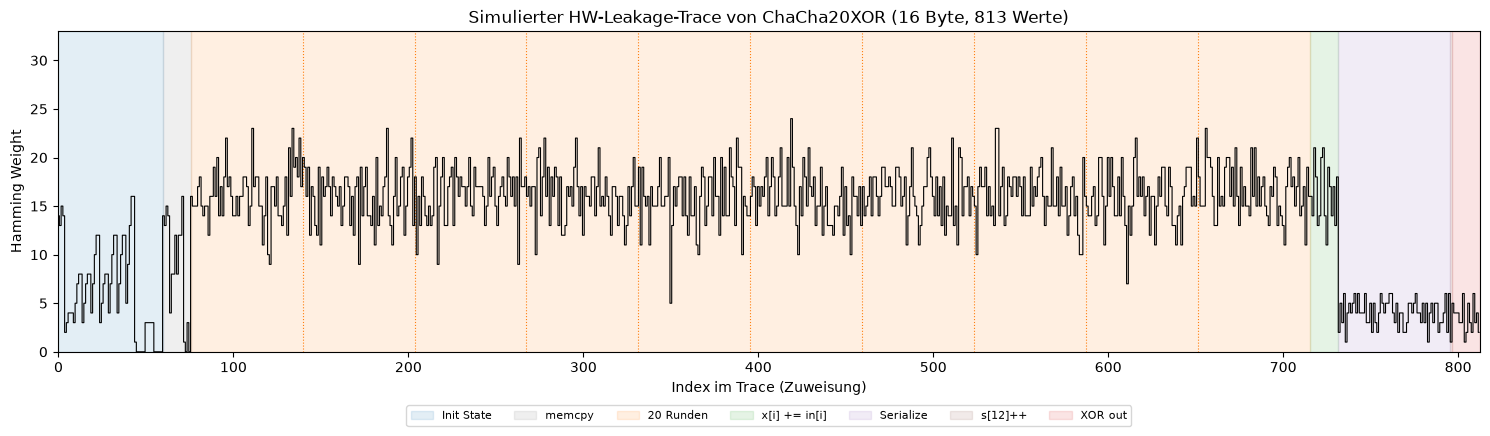

In [6]:
import matplotlib.pyplot as plt

hw_trace = []
chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16], hw_trace)

# Abschnitte des Traces (Indexbereiche für inlen = 16)
sections = [
    (0,   60,  "Init State",      "tab:blue"),
    (60,  76,  "memcpy",          "tab:gray"),
    (76,  716, "20 Runden",       "tab:orange"),
    (716, 732, "x[i] += in[i]",   "tab:green"),
    (732, 796, "Serialize",       "tab:purple"),
    (796, 797, "s[12]++",         "tab:brown"),
    (797, len(hw_trace), "XOR out", "tab:red"),
]

fig, ax = plt.subplots(figsize=(15, 4.5))
for start, end, label, color in sections:
    ax.axvspan(start - 0.5, end - 0.5, color=color, alpha=0.12, label=label)
for k in range(1, 10):                       # Grenzen der 10 Doppelrunden (je 8 QR x 8 Werte)
    ax.axvline(76 + 64 * k - 0.5, color="tab:orange", ls=":", lw=0.8)
ax.step(range(len(hw_trace)), hw_trace, where="mid", lw=0.8, color="black")
ax.set_xlim(-0.5, len(hw_trace) - 0.5)
ax.set_ylim(0, 33)
ax.set_xlabel("Index im Trace (Zuweisung)")
ax.set_ylabel("Hamming Weight")
ax.set_title(f"Simulierter HW-Leakage-Trace von ChaCha20XOR (16 Byte, {len(hw_trace)} Werte)")
ax.legend(loc="upper center", ncol=len(sections), fontsize=8, bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

## 4. Target validieren

In [7]:
def target_encrypt(key, ctr, nonce, pt):
    # Setzt Key/Counter/Nonce auf dem Target und verschlüsselt 16 Byte
    target.simpleserial_write('k', bytearray(key))
    if target.simpleserial_wait_ack() is None:
        raise IOError("kein ACK auf 'k'")
    target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + bytes(nonce)))
    if target.simpleserial_wait_ack() is None:
        raise IOError("kein ACK auf 'n'")
    target.simpleserial_write('p', bytearray(pt))
    ct = target.simpleserial_read('r', 16)
    if ct is None:
        raise IOError("keine Antwort auf 'p'")
    return bytes(ct)

# 1) RFC-Testvektor (die ersten 16 Byte)
ct = target_encrypt(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16])
print("RFC  target:", ct.hex())
print("RFC  ref   :", RFC_CT[:16].hex())
print("RFC  sim   :", chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16]).hex())
assert ct == RFC_CT[:16], "Target liefert beim RFC-Vektor ein falsches Ergebnis!"
assert ct == chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16]), "Target weicht beim RFC-Vektor von der Simulation ab!"

# 2) Zufallsvektoren: Target vs. pycryptodome und vs. Simulation
N_VALIDATE = 20
for i in range(N_VALIDATE):
    key, nonce, pt = os.urandom(32), os.urandom(12), os.urandom(16)
    ctr = rand_ctr()
    ct  = target_encrypt(key, ctr, nonce, pt)
    assert ct == chacha_ref(key, ctr, nonce, pt), f"Target != pycryptodome bei Vektor {i}"
    assert ct == chacha_sim(key, ctr, nonce, pt), f"Target != Simulation bei Vektor {i}"

print(f"Target stimmt bei RFC-Vektor + {N_VALIDATE} Zufallsvektoren mit pycryptodome und Simulation überein ✔")

RFC  target: 6e2e359a2568f98041ba0728dd0d6981
RFC  ref   : 6e2e359a2568f98041ba0728dd0d6981
RFC  sim   : 6e2e359a2568f98041ba0728dd0d6981
Target stimmt bei RFC-Vektor + 20 Zufallsvektoren mit pycryptodome und Simulation überein ✔


## 5. Trace-Länge bestimmen

`scope.adc.trig_count` zählt, wie viele ADC-Samples der Trigger high war, also wie lange `ChaCha20XOR()` läuft. Der CW-Lite kann maximal etwa 24 400 Samples pro Trace speichern.

In [8]:
key, nonce, pt = os.urandom(32), os.urandom(12), os.urandom(16)
ctr = 0
target.simpleserial_write('k', bytearray(key));  target.simpleserial_wait_ack()
target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + nonce));  target.simpleserial_wait_ack()

scope.adc.samples = 24400
scope.arm()
target.simpleserial_write('p', bytearray(pt))
if scope.capture():
    print("Timeout!")
target.simpleserial_read('r', 16)

trig_samples = scope.adc.trig_count
print("Trigger high für     :", trig_samples, "Samples")
print("ADC-Takt / Target-Takt:", scope.clock.adc_src)
print("Max. Samples (CW-Lite):", 24400)
if trig_samples > 24400:
    print("→ Der ganze Block passt nicht ins Fenster: scope.adc.offset nutzen oder nur die ersten Runden aufnehmen.")
else:
    print("→ Der ganze Block passt ins Fenster.")

Trigger high für     : 24280 Samples
ADC-Takt / Target-Takt: clkgen_x4
Max. Samples (CW-Lite): 24400
→ Der ganze Block passt ins Fenster.


Ein erster Trace zur Orientierung. Die 10 Doppelrunden sollten als sich wiederholendes Muster erkennbar sein:

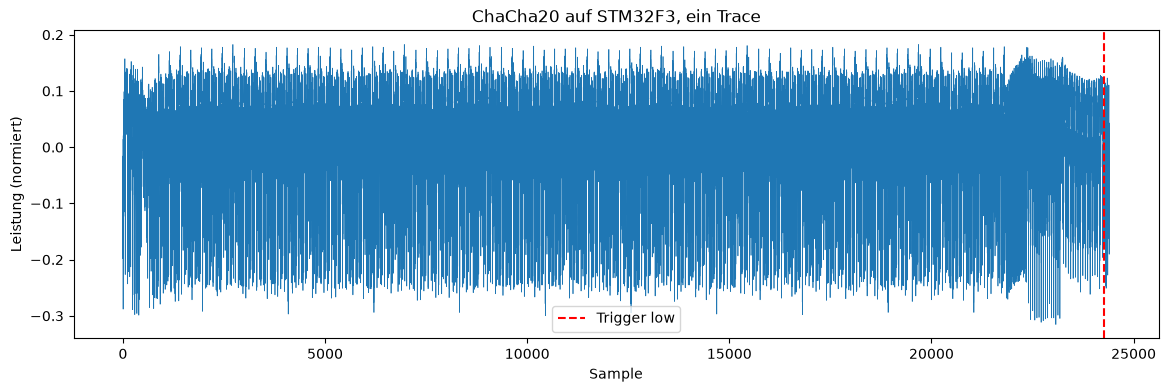

In [9]:
import matplotlib.pyplot as plt

trace = scope.get_last_trace()
plt.figure(figsize=(14, 4))
plt.plot(trace, lw=0.5)
plt.axvline(min(trig_samples, len(trace)), color='r', ls='--', label='Trigger low')
plt.xlabel("Sample"); plt.ylabel("Leistung (normiert)")
plt.title("ChaCha20 auf STM32F3, ein Trace")
plt.legend(); plt.show()

## 6. Traces aufnehmen

Fester (geheimer) Schlüssel, für jeden Trace zufälliger Counter und zufällige Nonce. Das entspricht dem Angreifermodell für eine CPA auf die ersten Quarterrounds: Die Wörter 12–15 sind bekannt und variieren. Jede Antwort wird gegen pycryptodome **und** gegen die Simulation geprüft. Nur Traces mit korrekter Antwort werden gespeichert.

**Nächste unabhängige Messreihe:** Dieselbe Firmware und dieselben ADC-/Takteinstellungen verwenden. Die Speicherzelle schreibt `chacha20_traces_validation.npz` und den 32-Byte-Testschlüssel getrennt nach `chacha20_validation_key.bin`; die alte `chacha20_traces.npz` bleibt erhalten. Der Testschlüssel darf erst **nach** der Kandidatenauswahl mit `cpa_frozen.py` verwendet werden. Vor dem neuen Lauf den bestehenden Kernelzustand beachten: Die Aufnahmezelle erzeugt einen neuen zufälligen Schlüssel.


In [10]:
from tqdm.notebook import trange

N       = 1000
SAMPLES = 5000        # nach Abschnitt 5 anpassen (max. 24400)
OFFSET  = 0           # Samples nach dem Trigger überspringen

scope.adc.samples = SAMPLES
scope.adc.offset  = OFFSET

# Festgelegte Aufnahmebedingungen für die neue Messreihe vor dem ersten Trace prüfen.
from pathlib import Path
import hashlib
EXPECTED_FW_SHA256 = "361084c757e4e09a0d382da9841bd86604f87c694f35a0912a34c81953ba0376"
actual_fw_sha256 = hashlib.sha256(
    (Path(FW_DIR) / f"simpleserial-chacha20-{PLATFORM}.hex").read_bytes()
).hexdigest()
assert actual_fw_sha256 == EXPECTED_FW_SHA256, "Firmware weicht vom Kalibrierungs-Build ab"
assert str(scope.clock.adc_src) == "clkgen_x4", "ADC-Taktquelle hat sich geändert"
assert np.isclose(float(scope.clock.clkgen_freq), 7_384_615.384615385, rtol=0.02)
# Der Treiber cached adc_freq; nach dem Setup neu synchronisieren und erst
# nach dem ADC-Lock messen, damit kein veralteter Startwert die Aufnahme stoppt.
import time
scope.clock.adc_src = "clkgen_x4"
scope.clock.reset_adc()
time.sleep(1)
assert scope.clock.adc_locked, "ADC-Takt ist nicht eingerastet"
actual_adc_freq = float(scope.clock.adc_freq)
print(f"ADC-Takt nach erneuter Messung: {actual_adc_freq:.0f} Hz")
assert np.isclose(actual_adc_freq, 29_542_304.0, rtol=0.02), (
    f"ADC-Takt {actual_adc_freq:.0f} Hz weicht vom Kalibrierungsaufbau ab"
)
assert int(scope.adc.samples) == 5000 and int(scope.adc.offset) == 0

key = os.urandom(32)  # fester Schlüssel: das Ziel der späteren CPA
target.simpleserial_write('k', bytearray(key)); target.simpleserial_wait_ack()

traces, ctrnonce_in, pt_in, ct_out = [], [], [], []
errors = 0          # Timeouts / keine Antwort
mismatch_ref = 0    # Antwort != pycryptodome
mismatch_sim = 0    # Antwort != Simulation

for i in trange(N, desc="Capturing traces"):
    nonce = os.urandom(12)
    ctr   = rand_ctr()
    pt    = os.urandom(16)

    target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + nonce))
    target.simpleserial_wait_ack()

    scope.arm()
    target.simpleserial_write('p', bytearray(pt))
    if scope.capture():
        print("Target timed out!"); errors += 1
        continue
    ct = target.simpleserial_read('r', 16)
    if ct is None:
        errors += 1
        continue
    ok_ref = bytes(ct) == chacha_ref(key, ctr, nonce, pt)
    ok_sim = bytes(ct) == chacha_sim(key, ctr, nonce, pt)
    mismatch_ref += not ok_ref
    mismatch_sim += not ok_sim
    if not (ok_ref and ok_sim):
        continue

    traces.append(scope.get_last_trace())
    ctrnonce_in.append(np.frombuffer(ctr.to_bytes(4, 'little') + nonce, dtype=np.uint8))
    pt_in.append(np.frombuffer(pt, dtype=np.uint8))
    ct_out.append(np.frombuffer(bytes(ct), dtype=np.uint8))

traces      = np.array(traces)
ctrnonce_in = np.array(ctrnonce_in)
pt_in       = np.array(pt_in)
ct_out      = np.array(ct_out)
print(f"{len(traces)} gültige Traces, {errors} Timeouts, "
      f"{mismatch_ref} Abweichungen zu pycryptodome, {mismatch_sim} Abweichungen zur Simulation")

AssertionError: 

In [ ]:
from pathlib import Path
import hashlib
from datetime import datetime, timezone

DATASET_FILE = Path("chacha20_traces_validation.npz")
KEY_FILE = Path("chacha20_validation_key.bin")
assert len(traces) == N == 1000, "Für die unabhängige Prüfung genau 1000 gültige Traces aufnehmen"
assert traces.shape[1] == SAMPLES == 5000 and OFFSET == 0
assert len({bytes(row[4:]) for row in ctrnonce_in}) == N, "Nonces müssen verschieden sein"
assert not DATASET_FILE.exists() and not KEY_FILE.exists(), "Vorhandene Validierungsdateien nicht überschreiben"

firmware_file = Path(FW_DIR) / f"simpleserial-chacha20-{PLATFORM}.hex"
firmware_sha256 = hashlib.sha256(firmware_file.read_bytes()).hexdigest()
with KEY_FILE.open("xb") as key_output:
    key_output.write(key)
KEY_FILE.chmod(0o600)

np.savez(DATASET_FILE,
         traces=traces, ctrnonce=ctrnonce_in, pt=pt_in, ct=ct_out,
         firmware_sha256=firmware_sha256,
         adc_samples=int(scope.adc.samples), adc_offset=int(scope.adc.offset),
         adc_src=str(scope.clock.adc_src),
         adc_freq=float(scope.clock.adc_freq),
         clkgen_freq=float(scope.clock.clkgen_freq),
         capture_utc=datetime.now(timezone.utc).isoformat())
print(f"gespeichert: {DATASET_FILE} ({len(traces)} Traces)")
print(f"Validierungsschlüssel separat: {KEY_FILE} — erst nach der Kandidatenauswahl öffnen")
print(f"Firmware-SHA256: {firmware_sha256}")


In [ ]:
plt.figure(figsize=(14, 4))
for t in traces[:5]:
    plt.plot(t, lw=0.5)
plt.xlabel("Sample"); plt.title("Erste 5 Traces")
plt.show()

## Hardware trennen

In [3]:
scope.dis()
target.dis()

## 7. CPA-Modell für die ersten Quarterrounds

Die Simulation in `chacha20_sim.py` hängt nach jeder Zuweisung die Hamming Weight des neuen Werts an ihren Leakage-Trace. Für eine erste CPA wählen wir gezielt das **erste Update von `x[d]`** in jeder der vier Spalten-Quarterrounds. Bei 16 Byte Klartext sind das im simulierten Trace die Indizes 77, 85, 93 und 101. Diese Indizes sind keine ADC-Samplepositionen.

Für Wort `j` gilt zunächst `S_j = (C_j + K_j) mod 2^32` und danach `x[d] = rotl32(D_j XOR S_j, 16)`. `C_j` ist eine ChaCha-Konstante, `K_j` ein unbekanntes Schlüsselwort und `D_j` der bekannte Counter beziehungsweise ein Nonce-Wort. Wir raten jeweils **ein Byte von `S_j`**. Das HW-Modell zählt die Einsen in `D_byte XOR guess`. Das HD-Modell zählt die Bitwechsel zwischen altem und neuem `x[d]`; es setzt voraus, dass dieser Übergang auf der Hardware tatsächlich sichtbar ist. Ob HW oder HD besser passt, entscheiden die Messungen.

Die folgende Zelle berechnet für jedes Kandidatenbyte eine Vorhersage pro Trace, korreliert sie mit einem frühen Samplefenster und prüft den gefundenen Zeitpunkt an der zweiten Hälfte der Traces. Der gespeicherte Schlüssel wird **erst nach der Suche** zur Kontrolle verwendet. Bei diesem XOR-Modell erzeugen `guess` und `guess XOR 0xff` betragsgleiche Korrelationen mit umgekehrtem Vorzeichen. Ein Kandidatenpaar ist deshalb noch kein eindeutig rekonstruiertes Schlüsselbyte.


Wort Byte  Kandidaten für S  Sample  r(Training)  r(Test)  Rang des wahren Paars
  0    0    33/cc            741    -0.493       -0.528      4
  0    1    02/fd             41    -0.504       -0.427      2
  0    2    00/ff             97    -0.567       -0.558      16
  0    3    15/ea            738    +0.536       +0.493      6
  1    0    06/f9           1005    -0.537       -0.372      5
  1    1    5b/a4            990    +0.483       +0.459      1
  1    2    00/ff            413    -0.603       -0.575      17
  1    3    00/ff            981    -0.550       -0.524      7
  2    0    11/ee           1277    +0.531       +0.550      2
  2    1    54/ab           1257    -0.546       -0.494      1
  2    2    06/f9           1337    +0.406       +0.332      2
  2    3    63/9c           1270    +0.385       +0.360      3
  3    0    52/ad           1522    +0.399       +0.383      1
  3    1    00/ff           1717    -0.527       -0.445      2
  3    2    00/ff            949   

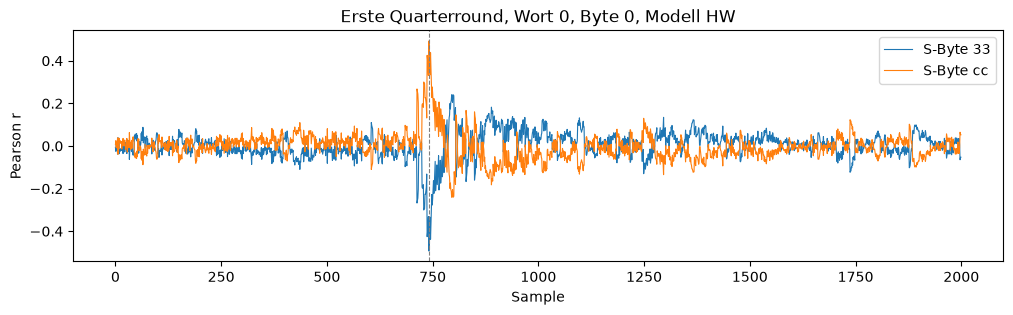

HW-Modell der ersten vier x[d]-Updates stimmt mit der Simulation überein.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from chacha20_sim import ChaCha20XOR as sim_ChaCha20XOR

# Erste Spalten-Quarterround: x[a] = C + K, danach x[d] = rotl32(x[d] XOR x[a], 16).
# Hypothese g ist ein Byte von S = (C + K) mod 2**32, nicht direkt ein Key-Byte.
LEAKAGE_MODEL = "HW"  # "HW" für den neuen Wert, "HD" für alten vs. neuen x[d]-Wert
SAMPLE_START = 0
SAMPLE_END = 2000  # frühe Quarterrounds; bei anderen Takten anhand der Traces prüfen
C = (0x61707865, 0x3320646e, 0x79622d32, 0x6b206574)

with np.load("chacha20_traces.npz") as saved:
    measured = saved["traces"].astype(np.float32)
    known = saved["ctrnonce"]
    check_key = saved["key"]  # ausschließlich nach der Kandidatensuche verwendet
    check_pt = saved["pt"][0]
    check_ct = saved["ct"][0]

assert measured.ndim == 2 and known.shape == (len(measured), 16)
assert len(measured) >= 20 and 0 <= SAMPLE_START < SAMPLE_END <= measured.shape[1]
assert LEAKAGE_MODEL in ("HW", "HD")
window = measured[:, SAMPLE_START:SAMPLE_END]
train = np.arange(len(measured)) % 2 == 0
test = ~train

# Pearson-Korrelation für alle Hypothesen gegen alle Samples im Fenster.
# Jede Spalte wird über die Trace-Achse zentriert und auf Länge 1 normiert.
def centered_unit_columns(matrix):
    x = matrix.astype(np.float32, copy=True)
    x -= x.mean(axis=0, keepdims=True)
    norm = np.sqrt(np.sum(x * x, axis=0, keepdims=True))
    return np.divide(x, norm, out=np.zeros_like(x), where=norm != 0)

train_samples = centered_unit_columns(window[train])
hw8 = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(axis=1).astype(np.float32)
guesses = np.arange(256, dtype=np.uint8)
results = []

print("Wort Byte  Kandidaten für S  Sample  r(Training)  r(Test)  Rang des wahren Paars")
for word in range(4):
    for byte in range(4):
        # Rotation um 16 Bit verschiebt Byte b an Position (b+2)%4.
        old_byte = known[:, 4 * word + byte]
        if LEAKAGE_MODEL == "HW":
            public_part = old_byte
        else:
            old_output_byte = known[:, 4 * word + (byte + 2) % 4]
            public_part = np.bitwise_xor(old_byte, old_output_byte)
        predicted = hw8[np.bitwise_xor(public_part[:, None], guesses[None, :])]
        correlations = centered_unit_columns(predicted[train]).T @ train_samples
        guess, local_sample = np.unravel_index(np.argmax(np.abs(correlations)), correlations.shape)
        sample = SAMPLE_START + local_sample
        pair = tuple(sorted((int(guess), int(guess) ^ 0xff)))
        train_r = float(correlations[guess, local_sample])
        test_h = centered_unit_columns(predicted[test, guess:guess + 1])[:, 0]
        test_y = centered_unit_columns(measured[test, sample:sample + 1])[:, 0]
        test_r = float(test_h @ test_y)

        # Kontrolle erst nach der Suche: der bekannte Schlüssel beeinflusst keine Hypothese.
        key_word = int.from_bytes(check_key[4 * word:4 * word + 4], "little")
        true_s = (C[word] + key_word) & 0xffffffff
        true_byte = (true_s >> (8 * byte)) & 0xff
        pair_scores = np.maximum(np.max(np.abs(correlations[:128]), axis=1),
                                 np.max(np.abs(correlations[255:127:-1]), axis=1))
        true_pair = min(true_byte, true_byte ^ 0xff)
        true_rank = 1 + int(np.sum(pair_scores > pair_scores[true_pair] + 1e-6))
        match = true_byte in pair
        results.append((word, byte, pair, sample, train_r, test_r, match, true_rank))
        print(f" {word:>2}   {byte:>2}    {pair[0]:02x}/{pair[1]:02x}           {sample:>4}    {train_r:+.3f}       {test_r:+.3f}      {true_rank}")

print(f"\n{sum(row[6] for row in results)}/16 echte S-Bytes liegen im jeweiligen Kandidatenpaar.")
print("XOR/HW und XOR/HD unterscheiden g und g^ff nur im Korrelationsvorzeichen.")
print("Die Paare sind daher noch keine eindeutige Rekonstruktion von K[4..7].")

# Beispiel: Korrelationsverlauf des ersten Wortes/Bytes für einen Kandidaten.
word, byte, pair, sample, _, _, _, _ = results[0]
public_part = known[:, 0] if LEAKAGE_MODEL == "HW" else np.bitwise_xor(known[:, 0], known[:, 2])
predicted = hw8[np.bitwise_xor(public_part[:, None], np.array(pair, dtype=np.uint8)[None, :])]
r_pair = centered_unit_columns(predicted[train]).T @ train_samples
plt.figure(figsize=(12, 3))
for candidate, row in zip(pair, r_pair):
    plt.plot(np.arange(SAMPLE_START, SAMPLE_END), row, lw=0.8, label=f"S-Byte {candidate:02x}")
plt.axvline(sample, color="gray", ls="--", lw=0.8)
plt.xlabel("Sample")
plt.ylabel("Pearson r")
plt.title(f"Erste Quarterround, Wort {word}, Byte {byte}, Modell {LEAKAGE_MODEL}")
plt.legend()
plt.show()

# Gegenprüfung gegen die bestehende Simulation für den ersten gespeicherten Trace:
# Trace-Indizes 77, 85, 93, 101 sind x[d] nach dem ersten Update der vier Spalten-QRs.
sim_trace = []
ctr0 = int.from_bytes(known[0, :4], "little")
nonce0 = bytes(known[0, 4:])
sim_out = [0] * 16
sim_ChaCha20XOR(check_key, ctr0, nonce0, check_pt, sim_out, 16, sim_trace)
assert bytes(sim_out) == bytes(check_ct)
for word in range(4):
    s = (C[word] + int.from_bytes(check_key[4 * word:4 * word + 4], "little")) & 0xffffffff
    d = int.from_bytes(known[0, 4 * word:4 * word + 4], "little")
    assert sim_trace[77 + 8 * word] == (d ^ s).bit_count()
print("HW-Modell der ersten vier x[d]-Updates stimmt mit der Simulation überein.")


Spalte j=1, Byte 0, Modell HW: Kandidatenpaar 06/f9, Trainings-Peak bei Sample 1005
Kandidat  : r(Training)=-0.537, r(Test)=-0.372
öffentlich: r(Training)=-0.191, r(Test)=-0.058


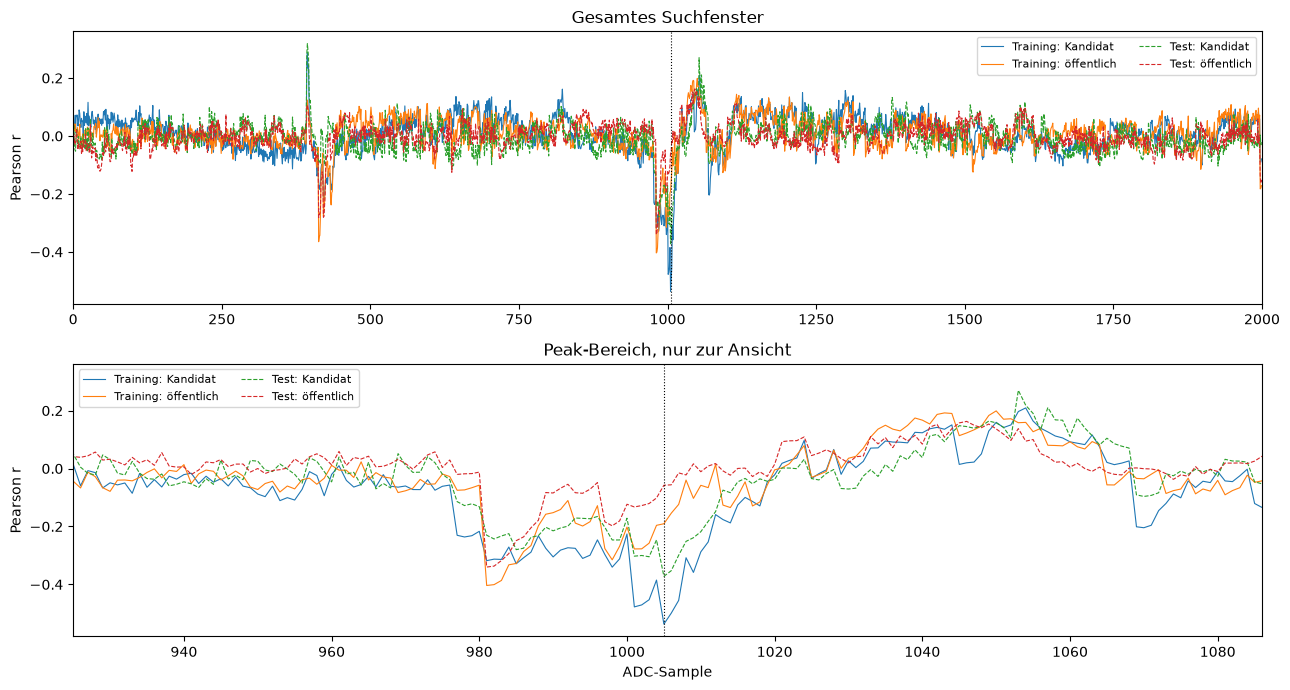

Ein Peak bestätigt noch nicht die ausgeführte Instruktion; öffentliche Daten können ebenfalls korrelieren.


In [5]:
# Offline-Diagnose für ein wählbares Byte nach der CPA-Zelle.
# Das gesamte Suchfenster bleibt sichtbar; der Trainings-Peak wird nur zusätzlich vergrößert.
DIAG_WORD = 1  # j=1: x[d] ist das erste Nonce-Wort (kein Nonce-Wert 1)
DIAG_BYTE = 0
assert 0 <= DIAG_WORD < 4 and 0 <= DIAG_BYTE < 4

diag_row = next(row for row in results if row[0] == DIAG_WORD and row[1] == DIAG_BYTE)
diag_guess, diag_sample = diag_row[2][0], diag_row[3]
diag_old = known[:, 4 * DIAG_WORD + DIAG_BYTE]
if LEAKAGE_MODEL == "HW":
    diag_public = diag_old
else:
    diag_other = known[:, 4 * DIAG_WORD + (DIAG_BYTE + 2) % 4]
    diag_public = np.bitwise_xor(diag_old, diag_other)

diag_hypothesis = hw8[np.bitwise_xor(diag_public, np.uint8(diag_guess))]
diag_control = hw8[diag_public]  # g=0: ausschließlich bekannte Eingaben
diag_x = np.arange(SAMPLE_START, SAMPLE_END)
diag_curves = {}
for name, mask in (("Training", train), ("Test", test)):
    diag_y = centered_unit_columns(measured[mask, SAMPLE_START:SAMPLE_END])
    for label, values in (("Kandidat", diag_hypothesis), ("öffentlich", diag_control)):
        diag_h = centered_unit_columns(values[mask, None])[:, 0]
        diag_curves[(name, label)] = diag_h @ diag_y

print(f"Spalte j={DIAG_WORD}, Byte {DIAG_BYTE}, Modell {LEAKAGE_MODEL}: "
      f"Kandidatenpaar {diag_row[2][0]:02x}/{diag_row[2][1]:02x}, "
      f"Trainings-Peak bei Sample {diag_sample}")
for label in ("Kandidat", "öffentlich"):
    print(f"{label:10s}: r(Training)={diag_curves[('Training', label)][diag_sample-SAMPLE_START]:+.3f}, "
          f"r(Test)={diag_curves[('Test', label)][diag_sample-SAMPLE_START]:+.3f}")

diag_lo = max(SAMPLE_START, diag_sample - 80)
diag_hi = min(SAMPLE_END, diag_sample + 81)
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, limits, title in ((axes[0], (SAMPLE_START, SAMPLE_END), "Gesamtes Suchfenster"),
                          (axes[1], (diag_lo, diag_hi), "Peak-Bereich, nur zur Ansicht")):
    for (name, label), curve in diag_curves.items():
        ax.plot(diag_x, curve, lw=0.8, ls="-" if name == "Training" else "--",
                label=f"{name}: {label}")
    ax.axvline(diag_sample, color="black", ls=":", lw=0.8)
    ax.set_xlim(*limits)
    ax.set_ylabel("Pearson r")
    ax.set_title(title)
    ax.legend(ncol=2, fontsize=8)
axes[-1].set_xlabel("ADC-Sample")
plt.tight_layout()
plt.show()
print("Ein Peak bestätigt noch nicht die ausgeführte Instruktion; öffentliche Daten können ebenfalls korrelieren.")


### Explorative Kalibrierung: ein gemeinsamer Zeitpunkt pro Spalte

Die bisherigen Peaks der vier Spalten liegen grob nacheinander. Wir untersuchen deshalb je Spalte ein kleines, **explorativ aus den vorhandenen Kurven gewähltes** Fenster. Innerhalb dieses Fensters bestimmen wir auf den Trainings-Traces einen gemeinsamen Samplepunkt für alle vier Bytes: Ein Kandidat muss stärker korrelieren als die Hypothese `g=0`, die nur bekannte Counter-/Nonce-Daten beschreibt. Danach wählen wir die Kandidatenpaare an genau diesem Samplepunkt und prüfen sie auf den zurückgehaltenen Traces.

Im Code wird der gespeicherte Schlüssel erst nach Sample- und Kandidatenwahl zur Bewertung der Ränge verwendet. **Die groben Fenster stammen aber aus einer vorherigen Analyse desselben Datensatzes, bei der auch der bekannte Schlüssel zur Diagnose benutzt wurde.** Das Ergebnis ist daher explorativ und kein vollständig blinder Angriffsnachweis. Für eine unabhängige Prüfung brauchen wir vorab festgelegte Fenster und einen neuen Datensatz, idealerweise mit anderem Schlüssel. Außerdem bleiben komplementäre Paare `g`/`g XOR ff` ununterscheidbar.


In [ ]:
# Nur Offline-Auswertung: verwendet die Variablen und NPZ-Daten aus der CPA-Zelle.
CAL_WINDOWS = ((650, 850), (900, 1100), (1150, 1400), (1400, 1650))
assert all(SAMPLE_START <= lo < hi <= SAMPLE_END for lo, hi in CAL_WINDOWS)
pair_guesses = np.arange(128, dtype=np.uint8)  # g und g XOR ff bilden ein Paar
test_samples = centered_unit_columns(measured[test, SAMPLE_START:SAMPLE_END])
cal_results = []
cal_scores = []
print("Spalte Sample Byte Paar     r(Train) r(Test) Rang(Train/Test)")
for word, (lo, hi) in enumerate(CAL_WINDOWS):
    joint_score = np.zeros(hi - lo, dtype=np.float32)
    word_models = []
    for byte in range(4):
        public_byte = known[:, 4 * word + byte]
        predicted = hw8[np.bitwise_xor(public_byte[:, None], pair_guesses[None, :])]
        r_train = centered_unit_columns(predicted[train]).T @ train_samples[:, lo-SAMPLE_START:hi-SAMPLE_START]
        # g=0 ist reine Eingabeverarbeitung; dessen Betrag als Kontrollsignal abziehen.
        gain = np.maximum(np.max(np.abs(r_train[1:]), axis=0) - np.abs(r_train[0]), 0)
        joint_score += gain * gain
        word_models.append((predicted, r_train))
    sample = lo + int(np.argmax(joint_score))  # Schlüssel wird hier nicht verwendet
    cal_scores.append((lo, hi, joint_score, sample))
    key_word = int.from_bytes(check_key[4 * word:4 * word + 4], "little")
    true_s = (C[word] + key_word) & 0xffffffff
    for byte, (predicted, r_train) in enumerate(word_models):
        at_sample = r_train[:, sample - lo]
        guess = int(np.argmax(np.abs(at_sample)))
        r_test = centered_unit_columns(predicted[test]).T @ test_samples[:, sample-SAMPLE_START]
        true_byte = (true_s >> (8 * byte)) & 0xff
        true_pair = min(true_byte, true_byte ^ 0xff)  # erst nach der Suche prüfen
        rank_train = 1 + int(np.sum(np.abs(at_sample) > abs(at_sample[true_pair]) + 1e-6))
        rank_test = 1 + int(np.sum(np.abs(r_test) > abs(r_test[true_pair]) + 1e-6))
        cal_results.append((word, byte, sample, guess, rank_train, rank_test))
        print(f"  {word}    {sample:4d}   {byte}  {guess:02x}/{guess ^ 0xff:02x}   "
              f"{at_sample[guess]:+.3f}   {r_test[guess]:+.3f}      {rank_train}/{rank_test}")

print(f"Rang 1: Training {sum(r[4] == 1 for r in cal_results)}/16, "
      f"Test {sum(r[5] == 1 for r in cal_results)}/16.")
print("Explorative Fenster aus diesem Datensatz; trotz Test-Hälfte noch kein vollständig blinder Angriffsnachweis.")
fig, ax = plt.subplots(figsize=(12, 3))
for word, (lo, hi, score, sample) in enumerate(cal_scores):
    ax.plot(np.arange(lo, hi), score, lw=1, label=f"Spalte {word}: Sample {sample}")
    ax.axvline(sample, color=f"C{word}", ls=":", lw=0.8)
ax.set_xlabel("ADC-Sample")
ax.set_ylabel("Gemeinsamer Score")
ax.set_title("Zeitpunktwahl je Spalte ohne Validierungsschlüssel")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


### Explorativ: vier Byte-Paare als 32-Bit-Wort

Das Byte-HW-Modell bewertet jedes Byte getrennt. Hier werden die vier besten Paare einer Spalte zu 16 möglichen Wörtern `S = C + K` zusammengesetzt. Die Hypothese ist das Hamming-Gewicht des **ganzen** `D XOR S`-Worts am bereits gewählten Sample. Die 16 Wörter bilden acht globale Komplementpaare: `S` und `S XOR ffffffff` bleiben im Korrelationsbetrag gleich.

Dies ist ein **explorativer Modellvergleich auf denselben Traces und Samples**. Eine hohe Korrelation validiert weder die Zuordnung zu einer Maschineninstruktion noch eine unabhängige Schlüsselrekonstruktion. Der bekannte Schlüssel wird erst nach der Kandidatenauswahl zur Rangkontrolle verwendet.


In [ ]:
# Offline: setzt die CPA- und Kalibrierungszellen voraus; keine neue Messung.
print("Spalte Sample  bestes S-Wortpaar       bestes K-Wortpaar       r(Train/Test)  Rang wahre Klasse (Train/Test)")
word_results = []
for word in range(4):
    sample = cal_results[4 * word][2]
    byte_pairs = [cal_results[4 * word + byte][3] for byte in range(4)]
    # Ein Bit pro Byte entscheidet zwischen den beiden Werten des Paars.
    s_words = np.array([
        sum((byte_pairs[byte] ^ (0xff if (mask >> byte) & 1 else 0)) << (8 * byte)
            for byte in range(4))
        for mask in range(16)
    ], dtype=np.uint32)
    model = sum(
        hw8[np.bitwise_xor(known[:, 4 * word + byte, None],
                           ((s_words >> (8 * byte)) & 0xff).astype(np.uint8)[None, :])]
        for byte in range(4)
    )
    y_train = centered_unit_columns(measured[train, sample:sample + 1])
    y_test = centered_unit_columns(measured[test, sample:sample + 1])
    r_train = (centered_unit_columns(model[train]).T @ y_train)[:, 0]
    r_test = (centered_unit_columns(model[test]).T @ y_test)[:, 0]
    # mask und mask XOR 15 sind globale Komplemente; nur 8 Klassen werten.
    assert np.allclose(r_train[:8], -r_train[15:7:-1], atol=1e-5)
    best = int(np.argmax(np.abs(r_train[:8])))
    s0, s1 = int(s_words[best]), int(s_words[best ^ 15])
    k0, k1 = (s0 - C[word]) & 0xffffffff, (s1 - C[word]) & 0xffffffff

    # Validierung: erst jetzt den gespeicherten Schlüssel lesen.
    true_key = int.from_bytes(check_key[4 * word:4 * word + 4], "little")
    true_s = (C[word] + true_key) & 0xffffffff
    hits = np.flatnonzero(s_words == true_s)
    if len(hits):
        true_class = min(int(hits[0]), int(hits[0]) ^ 15)
        rank_train = 1 + int(np.sum(np.abs(r_train[:8]) > abs(r_train[true_class]) + 1e-6))
        rank_test = 1 + int(np.sum(np.abs(r_test[:8]) > abs(r_test[true_class]) + 1e-6))
        ranks = f"{rank_train}/{rank_test}"
    else:
        ranks = "nicht in 16"
    word_results.append((word, sample, (s0, s1), (k0, k1), ranks))
    print(f"  {word}     {sample:4d}   {s0:08x}/{s1:08x}  {k0:08x}/{k1:08x}   "
          f"{r_train[best]:+.3f}/{r_test[best]:+.3f}       {ranks}")
print("S und sein globales Komplement bleiben ununterscheidbar; K-Kandidaten sind keine eindeutig extrahierten Schlüsselwörter.")
